In [10]:
import pandas as pd
df=pd.read_csv(r"c:\Users\A\Desktop\sales_data.csv",encoding="ISO_8859-1")
df["Order_Date"]=pd.to_datetime(df["Order_Date"],format="%d/%m/%Y")

In [11]:
print(df.head(3))
print(df.dtypes)
df.shape


    Order_ID Order_Date Customer_ID Region       City    Segment Channel  \
0  ORD111444 2024-01-01   CUST10128   West       Pune  Corporate  Online   
1  ORD102034 2024-01-01   CUST10316   West  Ahmedabad  Corporate  Online   
2  ORD106623 2024-01-01   CUST11764  South    Chennai   Consumer  Online   

         Category    Subcategory Product_ID  ...  Discount  Sales_INR  \
0  Home & Kitchen     Appliances      P1046  ...      0.00     654.30   
1          Beauty  Personal Care      P1048  ...      0.10    1711.99   
2  Home & Kitchen       Cookware      P1066  ...      0.05    5904.75   

   Discount_Amount_INR  Net_Sales_INR  Cost_INR  Profit_INR  Shipping_Days  \
0                 0.00         654.30    387.43      266.87              1   
1               171.20        1540.79    874.52      666.27              6   
2               295.24        5609.51   3095.78     2513.74              3   

   Returned  Customer_Satisfaction Payment_Method  
0        No                      4   

(15000, 22)

In [12]:
df.describe()
for col in["Region","City" ,"Channel","Category","Subcategory","Payment_Method"]:
       print(df[col].value_counts(),"\n")

Region
South      3561
West       3314
North      3217
Central    2489
East       2419
Name: count, dtype: int64 

City
Chennai        904
Bengaluru      904
Hyderabad      884
Mumbai         872
Kochi          869
Ahmedabad      838
Lucknow        832
Surat          818
Delhi          805
Jaipur         803
Pune           786
Chandigarh     777
Bhopal         652
Nagpur         650
Kolkata        622
Bhubaneswar    613
Patna          603
Indore         594
Raipur         593
Guwahati       581
Name: count, dtype: int64 

Channel
Online          8700
Retail Store    3319
Marketplace     2981
Name: count, dtype: int64 

Category
Technology         4231
Office Supplies    3358
Furniture          2859
Home & Kitchen     2642
Beauty             1910
Name: count, dtype: int64 

Subcategory
Laptops          1095
Accessories      1077
Phones           1040
Monitors         1019
Binders           884
Paper             867
Pens              823
Printers          784
Desks             740
Tables

In [13]:
print(df["Returned"].value_counts())
df["Returned"]=df["Returned"].map({"Yes":True,"No":False})
print(df["Returned"].isnull().sum())
print(df["Returned"].mean()*100)

Returned
No     13905
Yes     1095
Name: count, dtype: int64
0
7.3


In [14]:
print(df.groupby('Region')[['Sales_INR','Profit_INR']].sum().round(0))
print(df.columns)     

region=df.groupby('Region').agg(orders=('Order_ID','count'),sales=('Sales_INR','sum'),profit=('Profit_INR','sum'))
print(region)

region["profit_margin_in_%"]=(region["profit"]/region["sales"]*100).round(1)
region["avg_order_value"]=(region["sales"]/region["orders"]).round(0)
print(region.sort_values("sales",ascending=False))

          Sales_INR  Profit_INR
Region                         
Central  13395994.0   4533822.0
East     12999862.0   4370758.0
North    17430733.0   5895775.0
South    19256661.0   6461154.0
West     17868234.0   6017060.0
Index(['Order_ID', 'Order_Date', 'Customer_ID', 'Region', 'City', 'Segment',
       'Channel', 'Category', 'Subcategory', 'Product_ID', 'Quantity',
       'Unit_Price_INR', 'Discount', 'Sales_INR', 'Discount_Amount_INR',
       'Net_Sales_INR', 'Cost_INR', 'Profit_INR', 'Shipping_Days', 'Returned',
       'Customer_Satisfaction', 'Payment_Method'],
      dtype='str')
         orders        sales      profit
Region                                  
Central    2489  13395994.09  4533822.05
East       2419  12999862.27  4370757.72
North      3217  17430733.00  5895774.51
South      3561  19256660.63  6461153.66
West       3314  17868233.99  6017059.56
         orders        sales      profit  profit_margin_in_%  avg_order_value
Region                                   

Finding 1:South leads in sales and profit because it has the most orders. Profit margin of 33.7% and average order of ₹5400 are same across all region.

In [15]:
print(df.groupby("Discount")[["Sales_INR","Profit_INR"]].mean().round(0))
print(df.groupby("Discount").agg(orders=("Order_ID","count"),avg_profit=("Profit_INR","mean")).round(0))

          Sales_INR  Profit_INR
Discount                       
0.00         5298.0      2004.0
0.05         5449.0      1947.0
0.10         5436.0      1840.0
0.15         5401.0      1723.0
0.20         5476.0      1659.0
0.25         5266.0      1515.0
0.30         5612.0      1493.0
          orders  avg_profit
Discount                    
0.00        3731      2004.0
0.05        2356      1947.0
0.10        2910      1840.0
0.15        2496      1723.0
0.20        1792      1659.0
0.25        1133      1515.0
0.30         582      1493.0


Finding 2 :Average profit per order drops from ₹2004 at no discount to ₹1493 at 30% discount, average order value stays flat. Discount reduces profit without increasing order size.

Finding 3: Most orders (3731) are placed with no discount, and orders fall sharply at deeper discounts (582 orders at 30%). Higher discounts bring lower profit per order without larger order values, so deep discounts look like a poor trade-off.

In [16]:
summary=df.groupby('Discount').agg(orders=('Profit_INR','count'),avg_profit=('Profit_INR','mean'),total_profit=('Profit_INR','sum'),net_sales=('Net_Sales_INR','sum'))
summary["net_margin_%"]=(summary["total_profit"]/summary["net_sales"]*100).round(2)
print(summary)

          orders   avg_profit  total_profit    net_sales  net_margin_%
Discount                                                              
0.00        3731  2004.363377    7478279.76  19768042.30         37.83
0.05        2356  1947.066787    4587289.35  12195678.64         37.61
0.10        2910  1840.352416    5355425.53  14237550.13         37.61
0.15        2496  1722.624275    4299670.19  11458692.37         37.52
0.20        1792  1658.739615    2972461.39   7850879.48         37.86
0.25        1133  1515.164104    1716680.93   4474359.75         38.37
0.30         582  1492.715378     868760.35   2286311.01         38.00


Finding 4: Profit margin on net sales stays steady at about 38% across all discount levels, so discounts don't hurt the margin percentage. But they cut the actual profit earned per order, because discounted orders bring in less revenue while the order value before discount stays the same.  

chart : average profit per order falls as discount rises


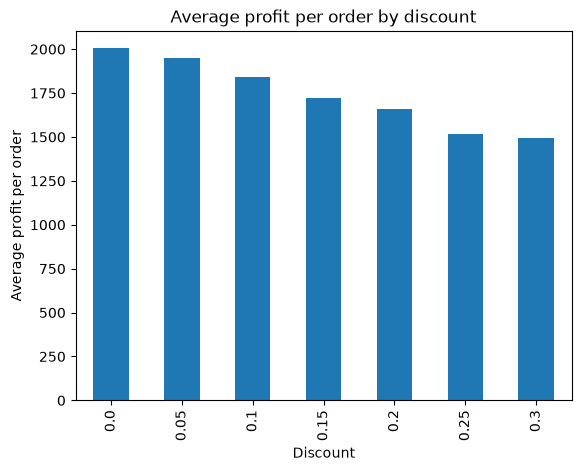

In [17]:
import matplotlib.pyplot as plt
summary["avg_profit"].plot(kind="bar")
plt.title("Average profit per order by discount")
plt.xlabel("Discount")
plt.ylabel("Average profit per order")
print("chart : average profit per order falls as discount rises")
plt.show()


Conclusion: Discounts do not pay off in this dataset. From 0% to 30% discount, average profit per order falls from ₹2004 to ₹1493, while order value stays flat and order counts drop at deeper discounts. Recommendation: keep discounts low, since deeper discounts reduce profit per order without bringing larger orders.